# HA1 — Graded abstractness simulator

**Self-contained submission notebook.** All HA1 calculations and plots are in the cells below; the only project input is `spatial_relations.csv`. The notebook works both in this `homework` folder and in [the repository](https://github.com/Uuu-7/Embodied-AI-and-Neurocomputational-Semantics) without importing a project `.py` file. Run the cells in order.

The selected inventory contains **20 Chinese and 20 English senses**. Nine earlier C-score questions have recorded decisions in the [feature audit](feature_score_audit.csv). Twenty-five reported taxonomy paths are available; fifteen S values remain NA. The recorded edge counts are checked below, but sense-to-synset matches have not all been independently revalidated. This notebook does not claim three independent ratings or LMS upload.

## 0. Environment and input location

The notebook reads `spatial_relations.csv` beside it and writes generated tables and figures to the same folder.

In [1]:
from pathlib import Path
from itertools import combinations
import platform

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display, Image

DATA_NAME = 'spatial_relations.csv'
current = Path.cwd().resolve()
matches = ((base / relative, base)
           for base in (current, *current.parents)
           for relative in (DATA_NAME,))
found = next(((path, base) for path, base in matches if path.is_file()), None)
if found is None:
    raise FileNotFoundError(f"Place {DATA_NAME} beside this notebook or run it within the repository")
data_file, repo = found
work = repo
work.mkdir(parents=True, exist_ok=True)
print("Input:", data_file.relative_to(repo))
print("Output folder:", work.relative_to(repo))
print("Python", platform.python_version(), "| NumPy", np.__version__, "| pandas", pd.__version__)

Input: spatial_relations.csv
Output folder: .
Python 3.13.14 | NumPy 2.5.3 | pandas 3.0.5


## 1. Validate the inventory and calculate C

Each selected literal sense has seven channels: Visual, Auditory, Tactile, Motor, Proprioceptive, Interoceptive, and Social. **0** means no typical direct grounding, **1** a conditional or secondary contribution, and **2** a characteristic contribution. The default raw C is the mean of the seven scores. Sum, maximum, and active-channel count are alternative aggregations for sensitivity checks.

In [2]:
FEATURES = (
    "visual_0_2",
    "auditory_0_2",
    "tactile_0_2",
    "motor_0_2",
    "proprioceptive_0_2",
    "interoceptive_0_2",
    "social_0_2",
)

def load_inventory(path: Path) -> pd.DataFrame:
    data = pd.read_csv(path, dtype={"concept_id": str, "language": str, "term": str})
    if len(data) != 40 or data["language"].value_counts().to_dict() != {"ZH": 20, "EN": 20}:
        raise ValueError("Expected exactly 20 Chinese and 20 English senses")
    if data["concept_id"].duplicated().any():
        raise ValueError("concept_id must be unique")
    if data[list(FEATURES)].isna().any().any():
        raise ValueError("Every selected sense needs seven channel scores")
    if not data[list(FEATURES)].isin([0, 1, 2]).all().all():
        raise ValueError("Channel scores must be 0, 1, or 2")
    totals = data.loc[:, FEATURES].astype(int).sum(axis=1)
    if not (totals == pd.to_numeric(data["C_sum"])).all():
        raise ValueError("Stored C_sum differs from the seven channel scores")
    if not np.allclose(totals / 14, pd.to_numeric(data["C_unit"]), atol=1e-6):
        raise ValueError("Stored C_unit differs from C_sum/14")
    return data

def compute_c_raw(data: pd.DataFrame, aggregation: str = "mean") -> pd.Series:
    """Keep C separate from S; the default raw C is the mean of seven 0–2 scores."""
    profile = data.loc[:, FEATURES].astype(float)
    if aggregation == "mean":
        return profile.mean(axis=1).rename("C_raw")
    if aggregation == "sum":
        return profile.sum(axis=1).rename("C_raw")
    if aggregation == "max":
        return profile.max(axis=1).rename("C_raw")
    if aggregation == "active_count":
        return profile.gt(0).sum(axis=1).astype(float).rename("C_raw")
    raise ValueError("aggregation must be mean, sum, max, or active_count")

In [3]:
inventory = load_inventory(data_file)
display(inventory[["concept_id", "language", "term", "target_sense_definition_en",
                   "category_parent", "C_sum", "S_depth"]].head(10))
print("Senses:", len(inventory), "| Chinese:", (inventory.language == "ZH").sum(),
      "| English:", (inventory.language == "EN").sum())

,concept_id,language,term,target_sense_definition_en,category_parent,C_sum,S_depth
0,ZH01,ZH,位置,A specified point or extent in a reference space.,spatial_location,4,3.0
1,ZH02,ZH,内部,The region enclosed by a reference entity.,bounded_region_relation,3,5.0
2,ZH03,ZH,外部,A region beyond the boundary of a reference en...,bounded_region_relation,3,NaN
3,ZH04,ZH,边界,A line delimiting the extent of an area.,spatial_limit,3,5.0
4,ZH05,ZH,中心,A central point fixed by the limits of a refer...,reference_point_relation,3,5.0
5,ZH06,ZH,前面,The part of an entity facing a specified obser...,oriented_location,3,6.0
6,ZH07,ZH,左侧,A region on the left of a reference entity und...,oriented_location,4,6.0
7,ZH08,ZH,坡度,The degree to which a surface inclines relativ...,spatial_arrangement,4,5.0
8,ZH09,ZH,上方,A region higher than a reference entity along ...,oriented_location,3,NaN
9,ZH10,ZH,下方,A region lower than a reference entity along t...,oriented_location,3,NaN


Senses: 40 | Chinese: 20 | English: 20


## 2. Calculate S from the reported taxonomy paths

S is the number of hypernym edges from a recorded root to the selected sense. The path-count function checks each reported depth against its node sequence. A missing or unsupported path remains NA. Pedagogical `category_parent` labels are not substituted for source-taxonomy paths.

In [4]:
def compute_s_raw(data: pd.DataFrame) -> pd.Series:
    """Count root-to-sense hypernym edges; unsupported paths remain NaN."""
    depths = []
    for row in data.itertuples(index=False):
        path = row.S_taxonomy_path
        reported = row.S_depth
        if pd.isna(path) or not str(path).strip():
            if not pd.isna(reported):
                raise ValueError(f"{row.concept_id}: S depth without taxonomy path")
            depths.append(np.nan)
            continue
        edges = len([node.strip() for node in str(path).split(">") if node.strip()]) - 1
        if pd.isna(reported) or edges != int(reported):
            raise ValueError(f"{row.concept_id}: path depth differs from reported S")
        depths.append(float(edges))
    return pd.Series(depths, index=data.index, name="S_raw")

## 3. Normalize C and S separately

Min–max scaling is computed over the observed values of each axis. The C×S plane uses 0.5 boundaries on these normalized axes; changing the inventory can change the coordinates.

In [5]:
def minmax_scale(values: pd.Series, name: str) -> pd.Series:
    """Scale observed, nonmissing values to [0, 1], preserving missing S."""
    valid = values.dropna().astype(float)
    if valid.empty or valid.max() == valid.min():
        raise ValueError(f"{name}: min–max scaling is undefined for these values")
    return ((values.astype(float) - valid.min()) / (valid.max() - valid.min())).rename(name)

def prepare_scores(data: pd.DataFrame, c_aggregation: str = "mean") -> pd.DataFrame:
    result = data.copy()
    result["C_raw"] = compute_c_raw(result, c_aggregation)
    result["S_raw"] = compute_s_raw(result)
    result["C_norm"] = minmax_scale(result["C_raw"], "C_norm")
    result["S_norm"] = minmax_scale(result["S_raw"], "S_norm")
    result["quadrant"] = np.where(
        result["S_norm"].isna(),
        "NA_S",
        np.where(result["C_norm"] >= 0.5, "high_C", "low_C")
        + "_"
        + np.where(result["S_norm"] >= 0.5, "high_S", "low_S"),
    )
    return result

In [6]:
scores = prepare_scores(inventory, c_aggregation="mean")
display(scores[["concept_id", "language", "term", "C_raw", "C_norm",
                "S_raw", "S_norm", "quadrant"]].head(10))
print("C raw range:", scores.C_raw.min(), "to", scores.C_raw.max())
print("S raw range:", scores.S_raw.min(), "to", scores.S_raw.max())
print("S missing:", scores.S_raw.isna().sum(), "of", len(scores))
assert np.allclose(scores.C_raw, scores[list(FEATURES)].mean(axis=1))
assert np.allclose(scores.C_norm.min(), 0) and np.allclose(scores.C_norm.max(), 1)
assert np.allclose(scores.S_norm.min(), 0) and np.allclose(scores.S_norm.max(), 1)
assert scores.S_raw.isna().sum() == 15
print("C/S and normalization checks passed.")

,concept_id,language,term,C_raw,C_norm,S_raw,S_norm,quadrant
0,ZH01,ZH,位置,0.571429,0.6,3.0,0.0,high_C_low_S
1,ZH02,ZH,内部,0.428571,0.4,5.0,0.4,low_C_low_S
2,ZH03,ZH,外部,0.428571,0.4,NaN,NaN,NA_S
3,ZH04,ZH,边界,0.428571,0.4,5.0,0.4,low_C_low_S
4,ZH05,ZH,中心,0.428571,0.4,5.0,0.4,low_C_low_S
5,ZH06,ZH,前面,0.428571,0.4,6.0,0.6,low_C_high_S
6,ZH07,ZH,左侧,0.571429,0.6,6.0,0.6,high_C_high_S
7,ZH08,ZH,坡度,0.571429,0.6,5.0,0.4,high_C_low_S
8,ZH09,ZH,上方,0.428571,0.4,NaN,NaN,NA_S
9,ZH10,ZH,下方,0.428571,0.4,NaN,NaN,NA_S


C raw range: 0.14285714285714285 to 0.8571428571428571
S raw range: 3.0 to 8.0
S missing: 15 of 40
C/S and normalization checks passed.


## 2. C×S plane

Dashed boundaries are at 0.5 on the normalized axes. The graph shows 25 senses with reported S paths; 15 S=NA rows remain in the CSV and are excluded from the plot. The path lengths are reproducible from the recorded node sequences; sense-to-synset matching remains an evidence limit.

In [7]:
def scatter_plot(scores: pd.DataFrame, output: Path) -> None:
    valid = scores.dropna(subset=["S_norm"])
    groups = list(valid.groupby(["C_norm", "S_norm"], sort=True))
    fig, (ax, key) = plt.subplots(1, 2, figsize=(15, 8),
                                  gridspec_kw={"width_ratios": [1.7, 1]},
                                  constrained_layout=True)
    key_lines = ["ID      (C, S)    Concept IDs", ""]
    for n, ((x, y), part) in enumerate(groups, 1):
        group_id = f"G{n:02d}"
        languages = set(part["language"])
        color = "#2465a5" if languages == {"ZH"} else "#d4772a" if languages == {"EN"} else "#7856a4"
        ax.scatter([x], [y], s=100 + 45 * (len(part) - 1), color=color,
                   edgecolors="white", linewidths=0.8, zorder=3)
        ax.annotate(group_id, (x, y), xytext=(6, 6), textcoords="offset points",
                    fontsize=8, color="#263238")
        ids = ", ".join(part["concept_id"])
        key_lines.append(f"{group_id}   ({x:.1f}, {y:.1f})   {ids}")
    ax.axvline(0.5, color="#555", linestyle="--", linewidth=1)
    ax.axhline(0.5, color="#555", linestyle="--", linewidth=1)
    ax.set(xlim=(-0.06, 1.12), ylim=(-0.06, 1.08), xlabel="C normalized (min–max)",
           ylabel="S normalized (min–max)", title=f"C × S: {len(valid)} reported paths")
    ax.grid(alpha=0.18)
    key.axis("off")
    key.text(0, 1, "\n".join(key_lines), va="top", ha="left", fontsize=9,
             fontfamily="monospace", linespacing=1.5)
    key.text(0, 0.05, "Blue: Chinese     Orange: English     Purple: shared coordinates\n"
             "Point size indicates how many concepts share a coordinate.\n"
             f"{scores['S_norm'].isna().sum()} S=NA rows are excluded from this plot.",
             va="bottom", fontsize=9)
    output.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(output, dpi=170, bbox_inches="tight")
    plt.close(fig)

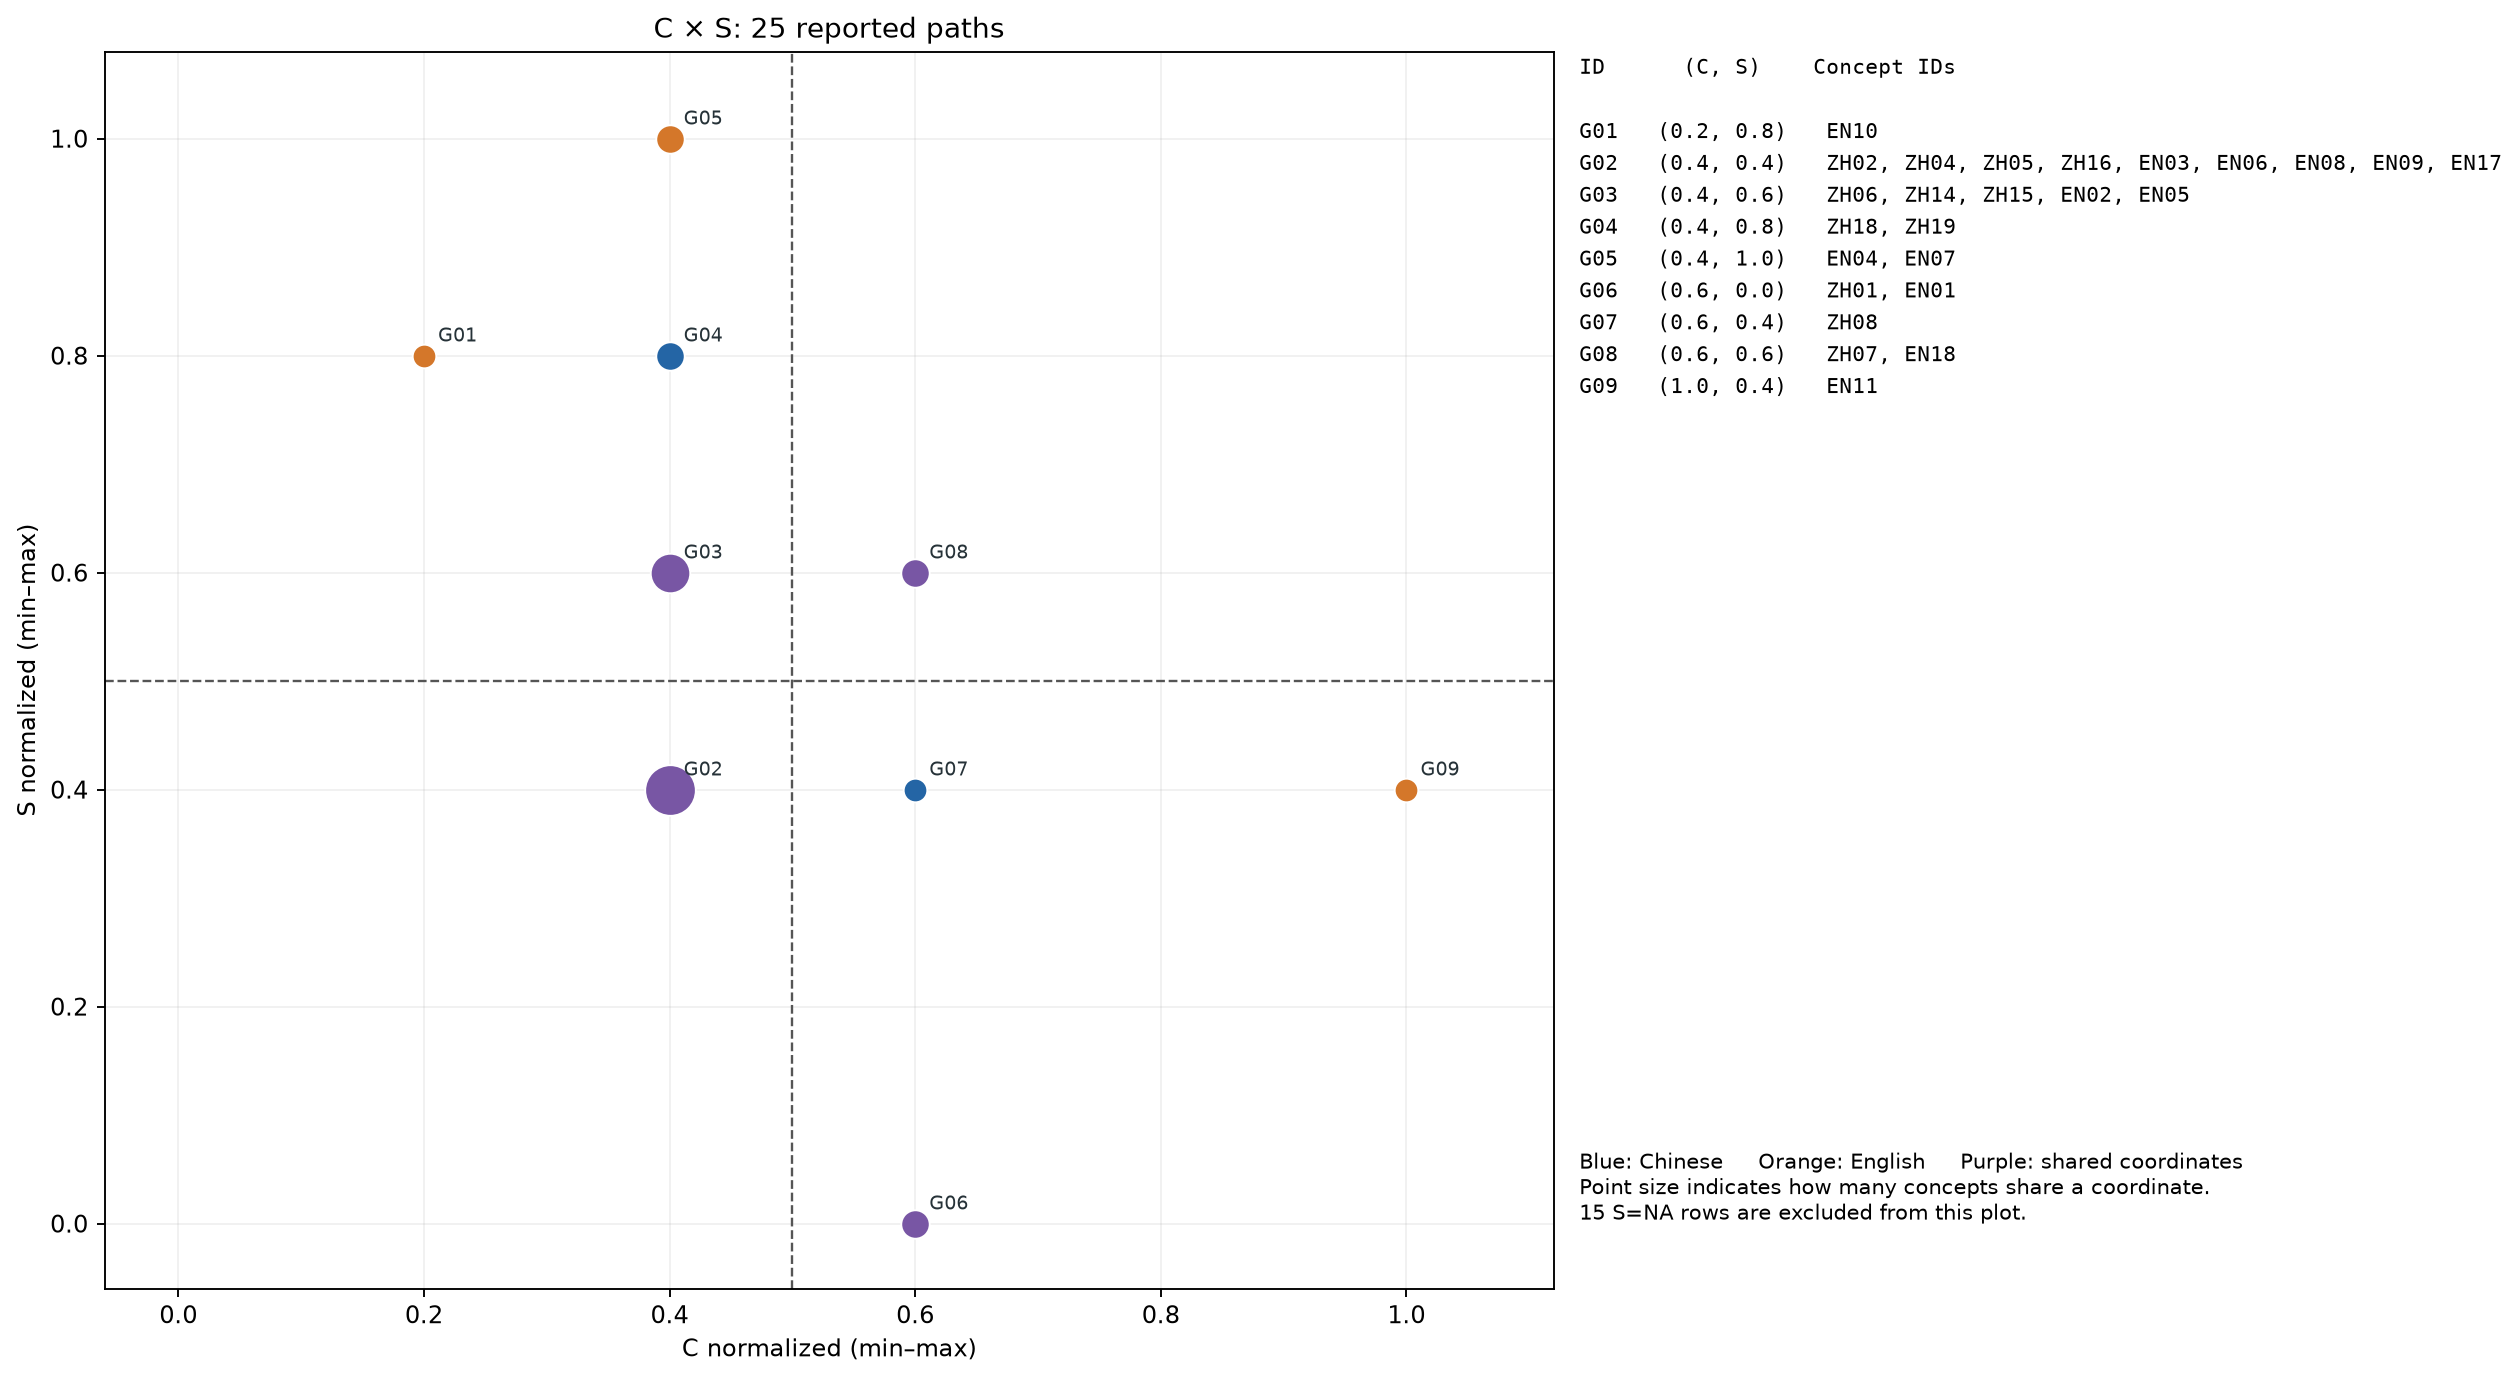

quadrant,low_C_low_S,low_C_high_S,high_C_low_S,high_C_high_S,NA_S
language,,,,,
EN,5,5,2,1,7
ZH,4,5,2,1,8


In [8]:
scatter_file = work / "figures/cs_scatter_ha1.png"
scatter_plot(scores, scatter_file)
display(Image(filename=str(scatter_file)))
display(pd.crosstab(scores.language, scores.quadrant).reindex(
    columns=["low_C_low_S","low_C_high_S","high_C_low_S","high_C_high_S","NA_S"],
    fill_value=0))

## 4. Adjustable abstractness A(w)

`A(w)=w(1−C_norm)+(1−w)(1−S_norm)` exposes the relative influence of grounding and specificity. The saved comparison uses w=0.2, 0.5, and 0.8. A live slider is available when `ipywidgets` is installed; the static table is readable without it. A stays NA when S is NA.

In [9]:
def abstractness(scores: pd.DataFrame, w: float) -> pd.Series:
    """A(w) = w(1-C_norm) + (1-w)(1-S_norm); S=NA stays missing."""
    if not 0 <= w <= 1:
        raise ValueError("w must be between 0 and 1")
    return (w * (1 - scores["C_norm"]) + (1 - w) * (1 - scores["S_norm"])).rename(
        f"A_{w:.1f}"
    )

def add_weight_settings(scores: pd.DataFrame) -> pd.DataFrame:
    result = scores.copy()
    for weight in (0.2, 0.5, 0.8):
        result[f"A_{weight:.1f}"] = abstractness(result, weight)
    return result

In [10]:
scores = add_weight_settings(scores)
assert scores.loc[scores.S_raw.isna(), ["S_norm", "A_0.2", "A_0.5", "A_0.8"]].isna().all().all()
display(scores[["concept_id", "term", "C_norm", "S_norm", "A_0.2", "A_0.5", "A_0.8"]].head(10))

,concept_id,term,C_norm,S_norm,A_0.2,A_0.5,A_0.8
0,ZH01,位置,0.6,0.0,0.88,0.7,0.52
1,ZH02,内部,0.4,0.4,0.60,0.6,0.60
2,ZH03,外部,0.4,NaN,NaN,NaN,NaN
3,ZH04,边界,0.4,0.4,0.60,0.6,0.60
4,ZH05,中心,0.4,0.4,0.60,0.6,0.60
5,ZH06,前面,0.4,0.6,0.44,0.5,0.56
6,ZH07,左侧,0.6,0.6,0.40,0.4,0.40
7,ZH08,坡度,0.6,0.4,0.56,0.5,0.44
8,ZH09,上方,0.4,NaN,NaN,NaN,NaN
9,ZH10,下方,0.4,NaN,NaN,NaN,NaN


In [11]:
def show_weight(w=0.5, top_n=10):
    table = scores[["concept_id", "language", "term", "C_norm", "S_norm"]].copy()
    table["A"] = abstractness(scores, w)
    return table.dropna(subset=["A"]).sort_values("A", ascending=False).head(top_n)

display(show_weight(0.5))
try:
    from ipywidgets import interact, FloatSlider
    interact(show_weight, w=FloatSlider(value=0.5, min=0, max=1, step=0.1,
                                        description="C weight"), top_n=(5, 25, 5))
except ImportError:
    print("Install ipywidgets for the live slider; show_weight(w) works without it.")


,concept_id,language,term,C_norm,S_norm,A
0,ZH01,ZH,位置,0.6,0.0,0.7
20,EN01,EN,location,0.6,0.0,0.7
1,ZH02,ZH,内部,0.4,0.4,0.6
4,ZH05,ZH,中心,0.4,0.4,0.6
3,ZH04,ZH,边界,0.4,0.4,0.6
25,EN06,EN,gap,0.4,0.4,0.6
22,EN03,EN,center,0.4,0.4,0.6
15,ZH16,ZH,路径,0.4,0.4,0.6
36,EN17,EN,path,0.4,0.4,0.6
27,EN08,EN,alignment,0.4,0.4,0.6


interactive(children=(FloatSlider(value=0.5, description='C weight', max=1.0), IntSlider(value=10, description…

## 4. Sensitivity and error analysis

The line plot varies w from 0 to 1 in steps of 0.1. A sense is called weight-sensitive when A changes by more than 0.1 between w=0.2 and 0.8; this is a descriptive threshold. Pair crossings count rank reversals. Mean, sum, maximum, and active-channel C aggregation rules expose model dependence. Nine earlier feature questions have recorded editorial decisions in [the feature audit](feature_score_audit.csv).

In [12]:
def weight_sensitivity_plot(scores: pd.DataFrame, output: Path) -> None:
    valid = scores.dropna(subset=["S_norm"])
    weights = np.linspace(0, 1, 11)
    fig, axes = plt.subplots(1, 2, figsize=(16, 8), sharey=True, constrained_layout=True)
    for ax, language in zip(axes, ("ZH", "EN")):
        part = valid.loc[valid["language"] == language]
        colors = plt.cm.tab20(np.linspace(0, 1, len(part)))
        for color, row in zip(colors, part.itertuples(index=False)):
            values = [w * (1 - row.C_norm) + (1 - w) * (1 - row.S_norm) for w in weights]
            ax.plot(weights, values, label=row.concept_id, color=color, linewidth=1.7)
        ax.set(title=f"{language} ({len(part)} senses)", xlabel="Weight w on (1 − C)",
               xlim=(0, 1), ylim=(-0.02, 1.02))
        ax.grid(alpha=0.2)
        ax.legend(title="Concept ID", loc="center left", bbox_to_anchor=(1.01, 0.5),
                  fontsize=8, frameon=False)
    axes[0].set_ylabel("Composite abstractness A(w)")
    fig.suptitle("Weight sensitivity: one line per concept with a reported S path")
    fig.text(0.5, 0.01, "Some concepts have identical C and S profiles, so their lines coincide.",
             ha="center", fontsize=9)
    output.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(output, dpi=170, bbox_inches="tight")
    plt.close(fig)

def crossing_pairs(scores: pd.DataFrame, low_weight: float = 0.2, high_weight: float = 0.8):
    valid = scores.dropna(subset=["S_norm"]).set_index("concept_id")
    first = abstractness(valid, low_weight)
    last = abstractness(valid, high_weight)
    crossing = []
    for left, right in combinations(valid.index, 2):
        delta_first = first.loc[left] - first.loc[right]
        delta_last = last.loc[left] - last.loc[right]
        if delta_first * delta_last < -1e-10:
            crossing.append((left, right))
    return crossing

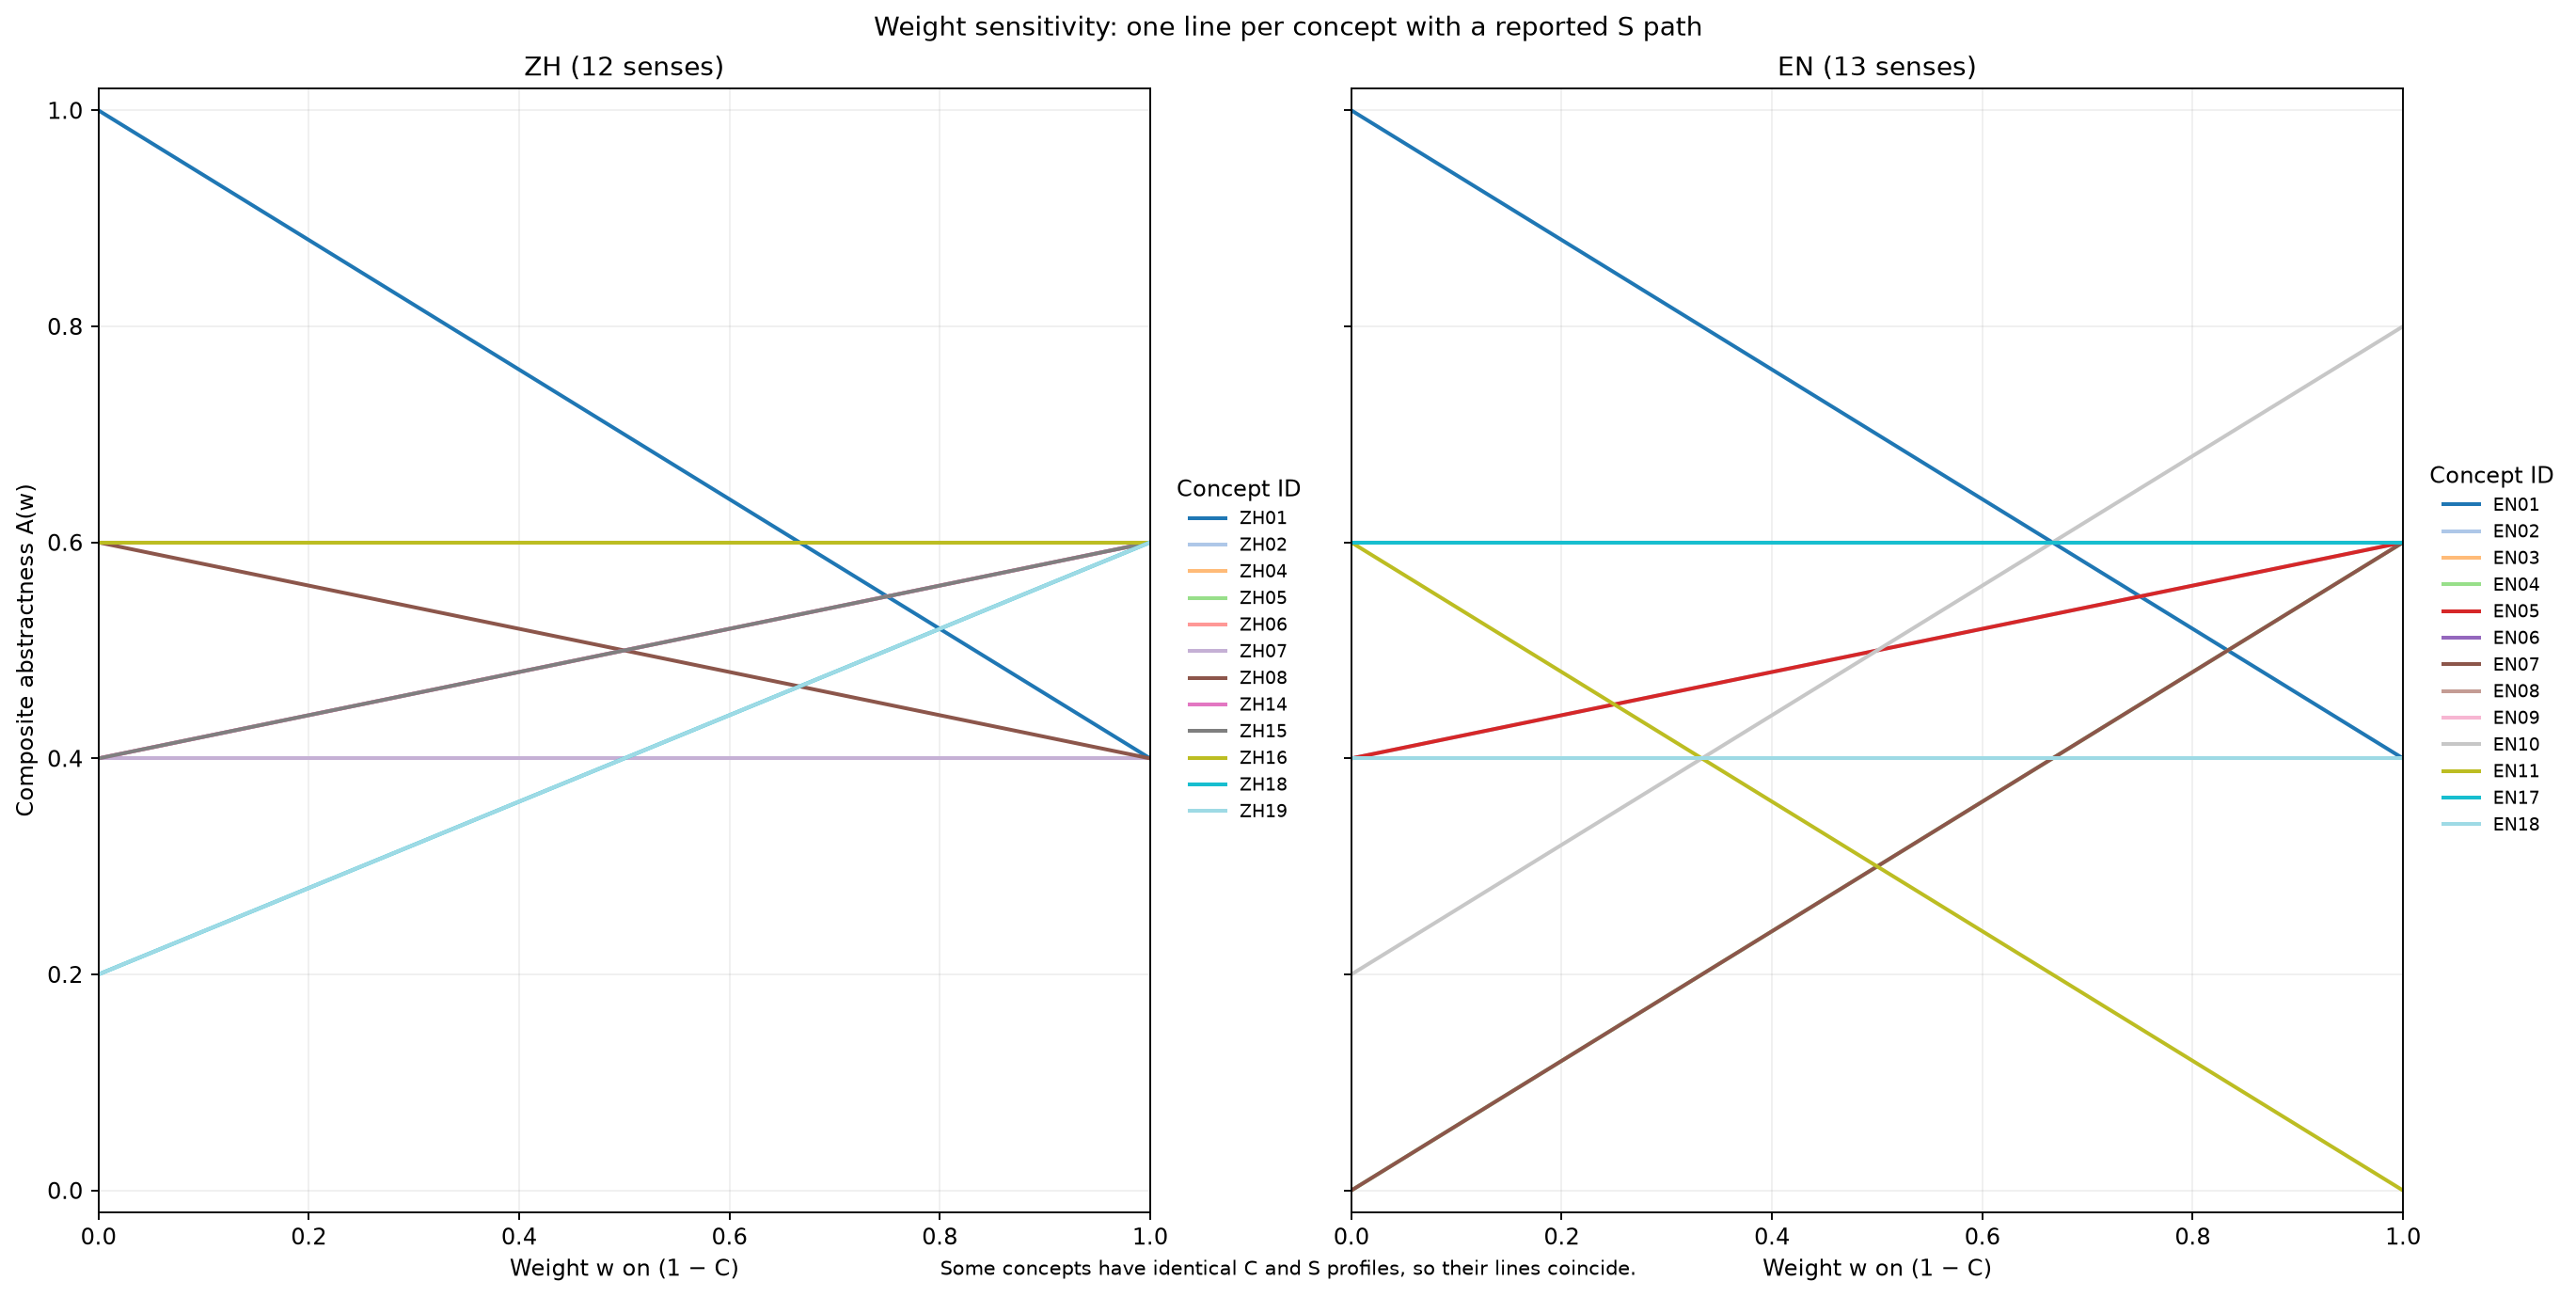

Weight-sensitive senses (>0.1): 14 of 25
Pairwise rank crossings: 76


,concept_id,term,C_norm,S_norm,A_0.2,A_0.8,weight_change
29,EN10,separation,0.2,0.8,0.32,0.68,0.36
20,EN01,location,0.6,0.0,0.88,0.52,0.36
0,ZH01,位置,0.6,0.0,0.88,0.52,0.36
23,EN04,proximity,0.4,1.0,0.12,0.48,0.36
26,EN07,adjacency,0.4,1.0,0.12,0.48,0.36
30,EN11,posture,1.0,0.4,0.48,0.12,0.36
18,ZH19,对称,0.4,0.8,0.28,0.52,0.24
17,ZH18,接触,0.4,0.8,0.28,0.52,0.24


Every fragile sense has a one-sentence explanation: True


In [13]:
sensitivity_file = work / "figures/weight_sensitivity_ha1.png"
weight_sensitivity_plot(scores, sensitivity_file)
display(Image(filename=str(sensitivity_file)))
valid = scores.dropna(subset=["S_norm"]).copy()
valid["weight_change"] = (valid["A_0.8"] - valid["A_0.2"]).abs()
print("Weight-sensitive senses (>0.1):", (valid.weight_change > 0.1).sum(), "of", len(valid))
print("Pairwise rank crossings:", len(crossing_pairs(scores)))
display(valid[["concept_id","term","C_norm","S_norm","A_0.2","A_0.8","weight_change"]]
        .sort_values("weight_change", ascending=False).head(8))
valid["fragile"] = valid["weight_change"] > 0.1
def explain_weight_change(row):
    if abs(row.C_norm - row.S_norm) < 1e-10:
        return "A stays constant because normalized C and S are equal."
    direction = "rises" if row.C_norm < row.S_norm else "falls"
    relation = "lower" if row.C_norm < row.S_norm else "higher"
    return (f"A {direction} by {row.weight_change:.2f} from w=0.2 to 0.8 because "
            f"normalized C is {relation} than normalized S for this target sense.")
valid["one_sentence_reason"] = valid.apply(explain_weight_change, axis=1)
print("Every fragile sense has a one-sentence explanation:", 
      valid.loc[valid.fragile, "one_sentence_reason"].notna().all())


In [14]:
sum_scaled = prepare_scores(inventory, c_aggregation="sum")
max_scaled = prepare_scores(inventory, c_aggregation="max")
active_scaled = prepare_scores(inventory, c_aggregation="active_count")
print("Mean vs sum normalized C, largest absolute difference:",
      (scores.C_norm - sum_scaled.C_norm).abs().max())
print("Max aggregation unique raw values:", sorted(compute_c_raw(inventory, "max").unique()))
print("Quadrant changes with max-channel C:",
      (scores.quadrant != max_scaled.quadrant).sum())
print("Mean vs active-channel-count Spearman rho:",
      scores.C_norm.corr(active_scaled.C_norm, method="spearman"))
print("Quadrant changes with active-channel-count C:",
      (scores.quadrant != active_scaled.quadrant).sum())
print("A(0.5) rank association with C-only:",
      scores["A_0.5"].corr(abstractness(scores, 1), method="spearman"))
print("A(0.5) rank association with S-only:",
      scores["A_0.5"].corr(abstractness(scores, 0), method="spearman"))


Mean vs sum normalized C, largest absolute difference: 1.1102230246251565e-16
Max aggregation unique raw values: [np.float64(1.0), np.float64(2.0)]
Quadrant changes with max-channel C: 19


Mean vs active-channel-count Spearman rho: 0.9624880093021152
Quadrant changes with active-channel-count C: 1
A(0.5) rank association with C-only: 0.1119496715018779
A(0.5) rank association with S-only: 0.7971889669385016


### Provenance and cutoff sensitivity

The integrated dataset has already removed the incompatible balance path. This check contrasts the lecture's **dataset-relative min–max C threshold** against the earlier team's fixed raw threshold `C_sum >= 5`, with the same `S_depth >= 6` rule. These cutoffs answer different descriptive questions and should not be merged into a single claim about coverage.

In [15]:
raw_cutoff = scores.copy()
raw_cutoff["raw_quadrant"] = np.where(
    raw_cutoff.S_raw.isna(), "NA_S",
    np.where(raw_cutoff[list(FEATURES)].sum(axis=1) >= 5, "high_C", "low_C")
    + "_" + np.where(raw_cutoff.S_raw >= 6, "high_S", "low_S")
)
display(pd.concat([
    scores.quadrant.value_counts().rename("HA1_minmax_0.5"),
    raw_cutoff.raw_quadrant.value_counts().rename("fixed_raw_cutoff")
], axis=1).fillna(0).astype(int))
print("S=NA is excluded from both four-quadrant comparisons.")

,HA1_minmax_0.5,fixed_raw_cutoff
NA_S,15,15
low_C_high_S,10,12
low_C_low_S,9,12
high_C_low_S,4,1
high_C_high_S,2,0


S=NA is excluded from both four-quadrant comparisons.


## 5. Export

The CSV keeps all 40 senses, including 15 with S=NA, and records raw/normalized C and S plus three A weight settings. Two PNG figures and a sensitivity-detail CSV are also saved. The generated CSVs use UTF-8 with a BOM so spreadsheet software on Windows recognizes Chinese text. Every channel score and its reason appears in [the 280-row feature audit](feature_score_audit.csv).

In [16]:
output = work / "ha1_scores_zh20_en20.csv"
export_cols = ["concept_id","language","term","semantic_family","C_rating_source",
               "C_raw","C_norm","S_raw","S_norm","S_source","quadrant",
               "A_0.2","A_0.5","A_0.8"]
scores[export_cols].to_csv(output, index=False, encoding="utf-8-sig", float_format="%.6f")
print("Saved:", output.relative_to(repo))
print("Saved:", scatter_file.relative_to(repo))
print("Saved:", sensitivity_file.relative_to(repo))
sensitivity_output = work / "ha1_weight_sensitivity_details.csv"
valid[["concept_id","language","term","C_norm","S_norm","A_0.2","A_0.8",
       "weight_change","fragile","one_sentence_reason"]].to_csv(
    sensitivity_output, index=False, encoding="utf-8-sig", float_format="%.6f")
print("Saved:", sensitivity_output.relative_to(repo))


Saved: ha1_scores_zh20_en20.csv
Saved: figures\cs_scatter_ha1.png
Saved: figures\weight_sensitivity_ha1.png
Saved: ha1_weight_sensitivity_details.csv


# HA1 interpretation

The simulator covers 20 Chinese and 20 English spatial-relation senses selected for HA0. Grounding C is the mean of seven ratings from 0 to 2. Specificity S is the number of edges in a reported root-to-sense taxonomy path. Each raw variable is normalized separately by its observed minimum and maximum. This makes the axes comparable within this inventory, although their values would shift if the inventory or paths changed. Twenty-five senses have reported paths; fifteen remain S=NA and receive no composite score. Missing evidence is never treated as low specificity.

With 0.5 dividers on the normalized axes, the 25 plotted senses occupy nine low-C/low-S, ten low-C/high-S, four high-C/low-S, and two high-C/high-S positions. Raw C ranges from 0.143 to 0.857 and raw S from three to eight edges. The quadrant counts describe this selected sample, not a balanced population. The four adopted feature revisions and the narrowed movement sense of *across* changed the earlier C distribution without being chosen to equalize quadrants.

The composite A(w)=w(1−C)+(1−w)(1−S) is evaluated at w=0.2, 0.5, and 0.8; the live control accepts any w between zero and one. Fourteen of 25 scorable senses change by more than 0.1 between the endpoint settings, and 76 sense pairs reverse rank. EN04 has lower normalized C than S, so its A increases as C receives more weight. EN11 has higher C than S and moves in the opposite direction. Reporting both axes alongside A prevents a single ranking from hiding these tradeoffs.

Mean and sum aggregation give identical normalized C because one is a constant multiple of the other. Maximum-channel and active-channel rules provide additional sensitivity checks. The v4 review log records a reason and provenance for all 280 ratings, including low-confidence conditional readings. However, those ratings are not three independent human annotations, and the inherited S paths have not all been rechecked against source synsets. The model is a reproducible computational proxy, not a validated measure of psychological abstractness.
